# Grocery Store Research: The Price Pulse of Long Island
## Phase 3: Final Implementation, Modeling, Evaluation, and Product-Regime Analysis

**Author:** Frank Valdez (Project Owner, Dataset Creator, and Domain Reviewer)  
**Project Title:** *Grocery Store Research — Predicting Weekly Price Changes in Long Island Grocery Catalogs*  
**Archive Window:** May 16, 2026 – September 6, 2026 (82 longitudinal retailer snapshots; 1,031,264 raw records)

---

### Executive Overview & Notebook Organization
This notebook contains the complete, reproducible end-to-end Python implementation for **Phase 3** of the *Grocery Store Research* project. Building upon the longitudinal catalog collection and leak-free preprocessing established in Phase 2, this notebook is organized into seven clearly labeled sections:

1. **Data Loading & Multi-Retailer Catalog Consolidation:** Verifies raw archive provenance, demonstrates exact-cent price parsing and string UPC preservation, reconciles duplicate category listings across four Long Island grocery chains (**King Kullen**, **Stop & Shop**, **Gala Baldwin**, **Gala Freeport**), and loads the cleaned catalog and King Kullen supervised modeling table.
2. **Exploratory Data Analysis (EDA) & Embedded Visualizations:** Visualizes longitudinal catalog coverage, schema-driven missingness, right-skewed price distributions, IQR outlier fences, weekly price-change prevalence, promotional rollback dynamics, and category-level variation.
3. **Data Preprocessing, Feature Engineering & Temporal Split Verification:** Documents the 10 past-only numeric features and 158 encoded primary-category indicators (`172` total transformed features), verifies the strict chronological boundary (`207,942` training rows through `2026-08-16` vs. `46,511` held-out test rows from `2026-08-23` to `2026-09-06`), and inspects training feature correlations.
4. **Data Modeling, Expanding-Window Temporal CV & Hyperparameter Tuning:** Introduces the five supervised classification families (**Logistic Regression**, **Linear SVM**, **Decision Tree**, **Random Forest**, **Histogram-Based Gradient Boosting**), executes 5-fold expanding-window temporal cross-validation with per-fold transformer refitting, evaluates the collinearity ablation check (`mean_abs_change_4` vs. `volatility_4`, $r = 0.98$), and tunes decision thresholds on validation predictions.
5. **Held-Out Test Evaluation, Subgroup Breakdowns & Error Analysis:** Compares all models against the **No-Change Majority Baseline** and **Observed Discount Heuristic** using Accuracy, Balanced Accuracy, Precision, Recall, Specificity, $F_1$ Score, ROC-AUC, PR-AUC (Average Precision), and Brier Score. Analyzes weekly stability, top-10 category performance, seen vs. unseen (cold-start) UPC generalization, permutation feature importance, and real product error case studies.
6. **Supplementary Unsupervised Learning — Product Pricing-Regime Clustering:** Applies **K-Means Clustering** to `20,150` training UPC behavioral profiles, evaluates cluster quality via **Silhouette Score**, **Davies-Bouldin Index**, and **Calinski-Harabasz Index**, and links discovered retail regimes to out-of-sample predictability.
7. **Summary Recommendation & Conclusions:** Synthesizes technical findings and deployment recommendations.

In [1]:
# =============================================================================
# 0. Environment Setup, Imports, and Reproducibility Configuration
# =============================================================================
from pathlib import Path
from decimal import Decimal, InvalidOperation, ROUND_HALF_UP
import json
import warnings
import platform
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Configure publication-quality plotting aesthetics matching the report
PALETTE = ["#164e63", "#b65b35", "#528a6c", "#9276a0", "#d97706", "#3b82f6"]
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 130,
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

P2_DIR = Path("phase-2-support")
P3_DIR = Path("phase-3-outputs")

print(f"Python version      : {platform.python_version()}")
print(f"pandas version      : {pd.__version__}")
print(f"NumPy version       : {np.__version__}")
print(f"scikit-learn version: {joblib.__name__ and __import__('sklearn').__version__}")

Python version      : 3.12.13
pandas version      : 3.1.0
NumPy version       : 2.5.4
scikit-learn version: 1.9.1


---
## 1. Data Loading & Multi-Retailer Catalog Consolidation

The *Long Island Grocery Catalog Observation Collection* comprises **82 longitudinal snapshots** across four retail grocery banners collected between **May 16, 2026** and **September 6, 2026** (`1,031,264` raw JSONL records; `161.58 MB` stored).

### Key Data Loading & Cleaning Rules
1. **String Identifier Preservation:** UPCs and retailer product keys are loaded strictly as text strings so leading zeros (e.g., `"00000000004510"`) are never stripped by integer inference.
2. **Exact Integer-Cent Price Parsing:** Prices are parsed via `Decimal` arithmetic (`ROUND_HALF_UP`) into positive integer cents (`current_cents`, `regular_cents`). Non-positive or missing prices remain `NaN`—never zero-filled.
3. **Timestamp & Timezone Reconciliation:** Evening snapshots collected in New York (`America/New_York`) that crossed midnight in UTC (`51,861` rows in Stop & Shop July 9 and Gala Baldwin July 17) are validated against both UTC and local dates and retained with an audit flag.
4. **Deduplicating Multi-Category Listings:** In King Kullen, a product listed under multiple store aisles appears once per category in raw snapshots (`79,230` repeated rows across `378,987` raw rows). After verifying **0 conflicting prices** per `(source, listing_id, date)`, duplicate rows are consolidated into a single observation with unioned category memberships (`299,757` unique King Kullen observations; `952,034` total across all four archives).

In [2]:
# =============================================================================
# 1.1 Demonstrate Exact-Cent Price Parsing & Load Consolidated Datasets
# =============================================================================
def parse_price_to_cents(raw_value):
    """Convert a raw price string/number into positive integer cents without float drift."""
    if raw_value is None or str(raw_value).strip() == "":
        return np.nan
    try:
        dec = Decimal(str(raw_value))
        if not dec.is_finite() or dec <= 0:
            return np.nan
        return int((dec * 100).quantize(Decimal("1"), rounding=ROUND_HALF_UP))
    except (InvalidOperation, ValueError):
        return np.nan

# Verify helper on edge cases
assert parse_price_to_cents("4.99") == 499
assert np.isnan(parse_price_to_cents("0.00"))
assert np.isnan(parse_price_to_cents(None))

# Load cleaned four-retailer catalog table and King Kullen supervised modeling table
clean_catalogs = pd.read_parquet(P2_DIR / "data/clean-catalogs.parquet")
kk_model_table = pd.read_parquet(P2_DIR / "data/king-kullen-model-table.parquet")
cleaning_summary = pd.read_csv(P2_DIR / "tables/cleaning-summary.csv")
example_records = pd.read_csv(P2_DIR / "tables/example-records.csv")

print(f"Consolidated 4-retailer catalog rows : {len(clean_catalogs):,}")
print(f"Eligible King Kullen labeled rows    : {len(kk_model_table):,}")
print(f"King Kullen unique labeled UPCs      : {kk_model_table['listing_id'].nunique():,}")

# Display archive-level cleaning and reconciliation summary
summary_cols = [
    "source", "snapshots", "start", "end", "raw_rows", "duplicate_rows",
    "clean_rows", "unique_ids", "conflicts", "price_above_regular", "stored_mb"
]
display(cleaning_summary[summary_cols].style.format({
    "raw_rows": "{:,}", "duplicate_rows": "{:,}", "clean_rows": "{:,}",
    "unique_ids": "{:,}", "price_above_regular": "{:,}", "stored_mb": "{:.2f}"
}))

print("\nSample cleaned King Kullen observations (September 6, 2026):")
display(example_records)

Consolidated 4-retailer catalog rows : 952,034
Eligible King Kullen labeled rows    : 254,453
King Kullen unique labeled UPCs      : 20,756


,source,snapshots,start,end,raw_rows,duplicate_rows,clean_rows,unique_ids,conflicts,price_above_regular,stored_mb
0,King Kullen,18,2026-05-16,2026-09-06,"378,987","79,230","299,757","21,040",0,0,98.82
1,Stop & Shop,3,2026-07-09,2026-07-19,"127,002",0,"127,002","43,216",0,0,17.98
2,Gala Baldwin,16,2026-07-17,2026-08-06,"149,505",0,"149,505","11,822",0,0,10.76
3,Gala Freeport,45,2026-07-23,2026-09-06,"375,770",0,"375,770","9,797",0,"13,763",34.01



Sample cleaned King Kullen observations (September 6, 2026):


,listing_id,name,primary_category,current_price,regular_cents,discount_depth
0,4510,Produce Dragon Beans,Trash Bags,10.25,1025.0,0.0
1,7313,TURKEY DINNER COLD (NT),Cheese-Deli Sliced,249.00,24900.0,0.0
2,7528,Fresh Baked Bagels,Bagels,1.19,119.0,0.0
3,7641,Bakery Linzer Tart,Bake Shop,2.49,249.0,0.0
4,30359,White Flesh Nectarines,Fresh Fruit,1.14,114.0,0.0


---
## 2. Exploratory Data Analysis (EDA) & Embedded Visualizations

Before training predictive models, we examine structural patterns across the four retail catalogs and within the 16 eligible weekly target windows of the King Kullen benchmark:
- **Coverage & Schema Heterogeneity:** Stop & Shop has the largest single-snapshot assortment (`42,409` items) but only 3 snapshots; Gala Freeport has 45 snapshots; King Kullen spans the full 16-week window (`2026-05-16` to `2026-09-06`). Schema-level missingness varies sharply: Gala Baldwin provides only `regular_price` (`100%` missing `current_price`), whereas Stop & Shop provides only `current_price` (`100%` missing `regular_price`).
- **Right-Skewed Price Distributions & Outliers:** Latest-snapshot median prices range from `$4.59` (Gala Freeport) to `$5.49` (Stop & Shop), with King Kullen at `$4.99` (IQR `$3.29–$7.99`). Although `915` King Kullen listings exceed the upper Tukey fence (`$15.04`), inspection confirms these are genuine catering platters and bulk packs (up to `$249.00` for *Turkey Dinner Cold*), so they are retained rather than winsorized or deleted.
- **Target Prevalence & Promotional Rollbacks:** Across `254,453` exact-7-day King Kullen pairs, `87.52%` (`222,695`) remain exactly unchanged, while `12.25%` (`31,176`) change by at least 5%. Items currently on promotional discount (`current_cents < regular_cents`) exhibit a **42.04%** probability of changing price by $\ge 5\%$ the following week, compared to **7.00%** for undiscounted items.

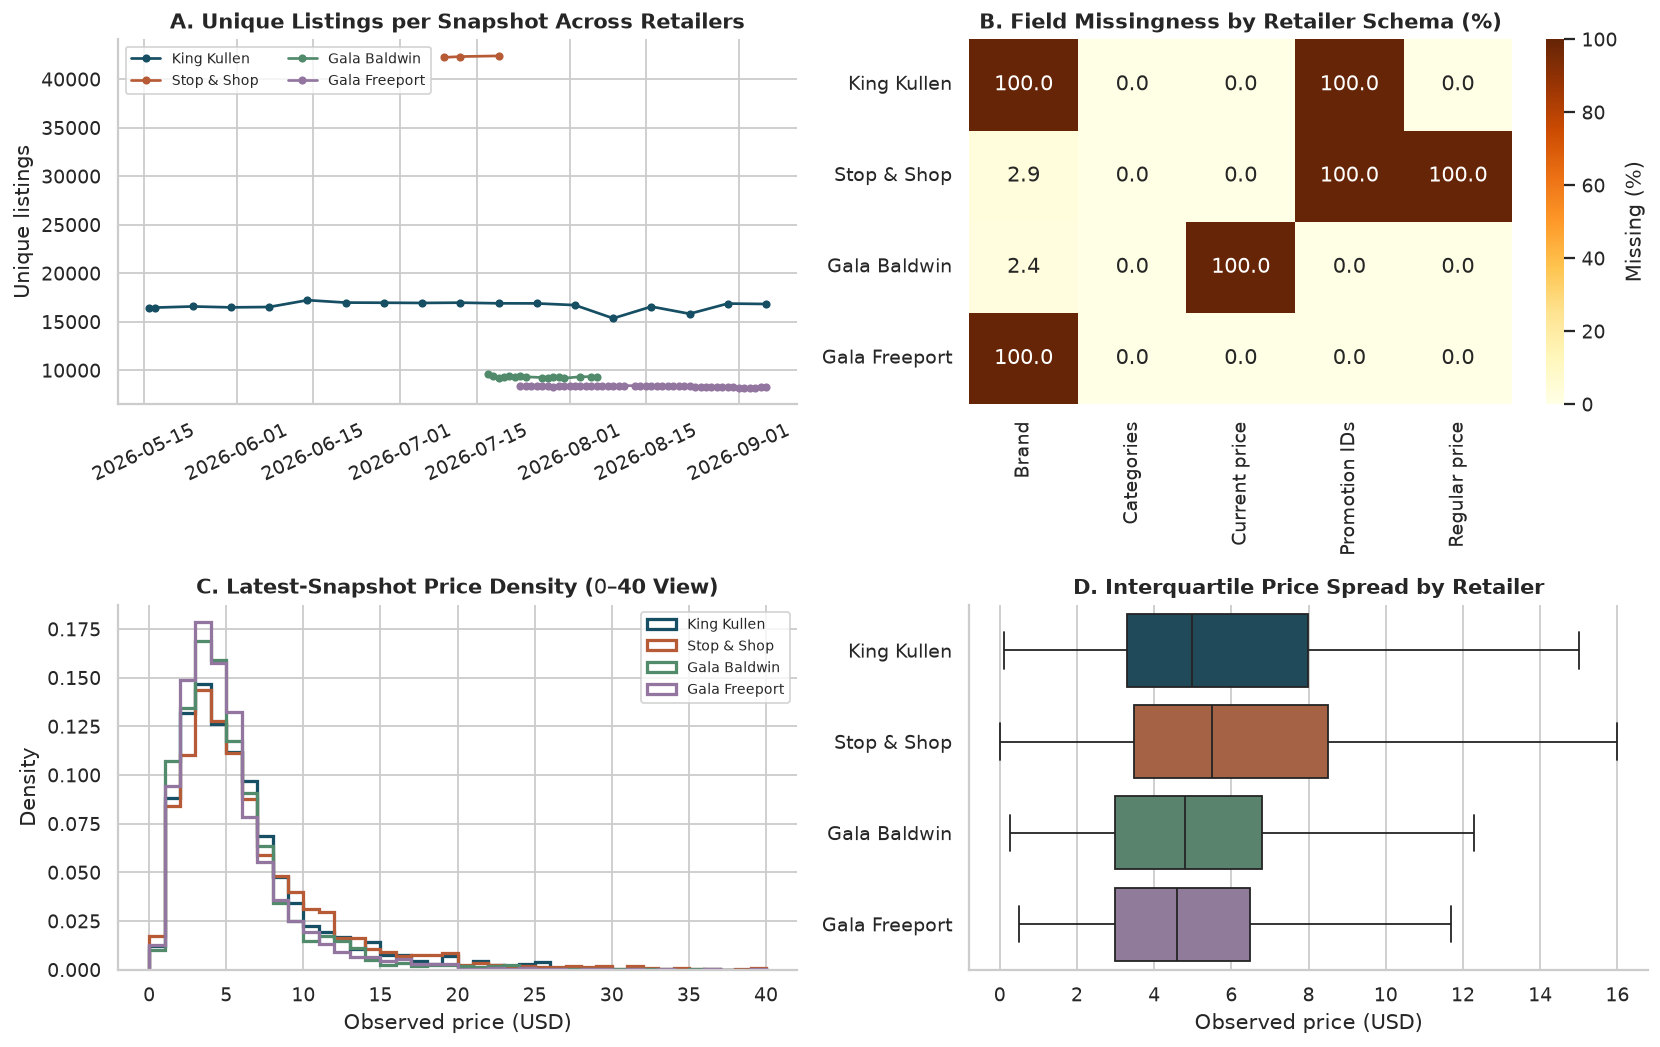

In [3]:
# =============================================================================
# 2.1 Visualize Catalog Coverage, Missingness, and Price Distributions
# =============================================================================
harmonized_miss = pd.read_csv(P2_DIR / "tables/harmonized-missingness.csv")
sources_order = ["King Kullen", "Stop & Shop", "Gala Baldwin", "Gala Freeport"]

fig, axs = plt.subplots(2, 2, figsize=(13, 8.2))

# Panel A: Snapshot coverage over time
for i, src in enumerate(sources_order):
    grp = clean_catalogs[clean_catalogs["source"] == src].groupby("date").size()
    axs[0, 0].plot(grp.index, grp.values, marker="o", markersize=3.5, label=src, color=PALETTE[i])
axs[0, 0].set_title("A. Unique Listings per Snapshot Across Retailers")
axs[0, 0].set_ylabel("Unique listings")
axs[0, 0].legend(fontsize=8, ncol=2)
axs[0, 0].tick_params(axis="x", rotation=25)

# Panel B: Schema missingness heatmap
miss_piv = harmonized_miss.pivot(index="source", columns="field", values="missing_pct").reindex(sources_order)
sns.heatmap(miss_piv, annot=True, fmt=".1f", cmap="YlOrBr", vmin=0, vmax=100, cbar_kws={"label": "Missing (%)"}, ax=axs[0, 1])
axs[0, 1].set_title("B. Field Missingness by Retailer Schema (%)")
axs[0, 1].set_xlabel("")
axs[0, 1].set_ylabel("")

# Panel C: Latest snapshot price density ($0-$40)
latest_snap = clean_catalogs.loc[clean_catalogs["date"].eq(clean_catalogs.groupby("source")["date"].transform("max"))].copy()
latest_snap["price_usd"] = latest_snap["observed_cents"] / 100.0
for i, src in enumerate(sources_order):
    vals = latest_snap.loc[latest_snap["source"] == src, "price_usd"]
    axs[1, 0].hist(vals, bins=np.linspace(0, 40, 41), histtype="step", linewidth=1.8, density=True, label=src, color=PALETTE[i])
axs[1, 0].set_title("C. Latest-Snapshot Price Density ($0–$40 View)")
axs[1, 0].set_xlabel("Observed price (USD)")
axs[1, 0].set_ylabel("Density")
axs[1, 0].legend(fontsize=8)

# Panel D: Boxplot of latest prices (excluding flier markers for legibility)
sns.boxplot(data=latest_snap, x="price_usd", y="source", order=sources_order, showfliers=False, palette=PALETTE[:4], ax=axs[1, 1])
axs[1, 1].set_title("D. Interquartile Price Spread by Retailer")
axs[1, 1].set_xlabel("Observed price (USD)")
axs[1, 1].set_ylabel("")

fig.tight_layout()
plt.show()

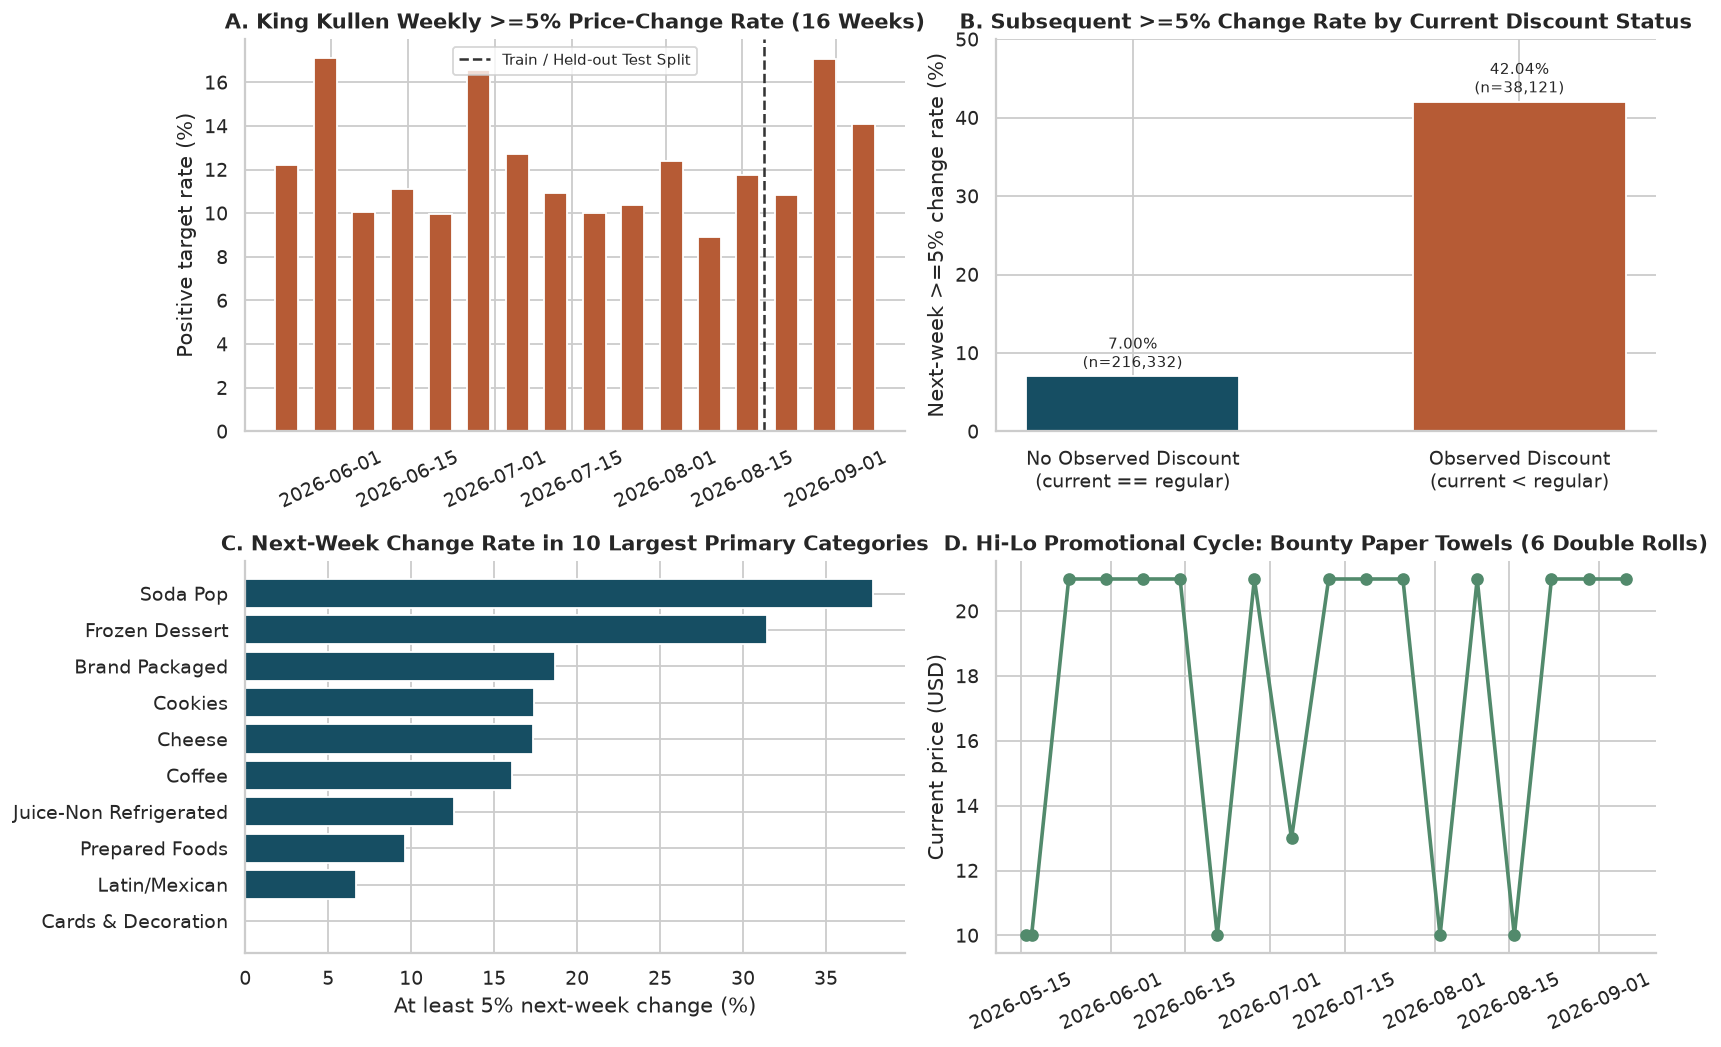

In [4]:
# =============================================================================
# 2.2 Visualize Weekly Price-Change Rates, Discount Effect, and Category Patterns
# =============================================================================
weekly_rates = pd.read_csv(P2_DIR / "tables/weekly-target-rates.csv")
weekly_rates["target_date"] = pd.to_datetime(weekly_rates["target_date"])
cat_rates = pd.read_csv(P2_DIR / "tables/category-target-rates.csv")
trace_df = pd.read_csv(P2_DIR / "tables/illustrative-price-trace.csv")
trace_df["date"] = pd.to_datetime(trace_df["date"])

fig, axs = plt.subplots(2, 2, figsize=(13, 8.2))

# Panel A: Weekly >=5% change rate across 16 target dates
axs[0, 0].bar(weekly_rates["target_date"], weekly_rates["rate"], width=4.2, color=PALETTE[1])
axs[0, 0].axvline(pd.Timestamp("2026-08-19"), color="#333", linestyle="--", linewidth=1.4, label="Train / Held-out Test Split")
axs[0, 0].set_title("A. King Kullen Weekly >=5% Price-Change Rate (16 Weeks)")
axs[0, 0].set_ylabel("Positive target rate (%)")
axs[0, 0].tick_params(axis="x", rotation=25)
axs[0, 0].legend(fontsize=8.5)

# Panel B: Next-week change rate by current discount status
disc_summary = kk_model_table.groupby("discount_flag")["target"].agg(["count", "mean"]).reset_index()
bars = axs[0, 1].bar(["No Observed Discount\n(current == regular)", "Observed Discount\n(current < regular)"], disc_summary["mean"] * 100.0, color=[PALETTE[0], PALETTE[1]], width=0.55)
axs[0, 1].set_title("B. Subsequent >=5% Change Rate by Current Discount Status")
axs[0, 1].set_ylabel("Next-week >=5% change rate (%)")
axs[0, 1].set_ylim(0, 50)
for idx, r in disc_summary.iterrows():
    axs[0, 1].text(idx, r["mean"] * 100.0 + 1.2, f"{r['mean']*100:.2f}%\n(n={int(r['count']):,})", ha="center", fontsize=8.5)

# Panel C: Top 10 primary categories by volume and their >=5% change rates
top10_c = cat_rates.head(10).sort_values("rate_pct", ascending=True)
axs[1, 0].barh(top10_c["primary_category"], top10_c["rate_pct"], color=PALETTE[0])
axs[1, 0].set_title("C. Next-Week Change Rate in 10 Largest Primary Categories")
axs[1, 0].set_xlabel("At least 5% next-week change (%)")

# Panel D: Illustrative hi-lo promotional price trace (Bounty Paper Towels)
axs[1, 1].plot(trace_df["date"], trace_df["current_price"], marker="o", linewidth=2, color=PALETTE[2])
axs[1, 1].set_title("D. Hi-Lo Promotional Cycle: Bounty Paper Towels (6 Double Rolls)")
axs[1, 1].set_ylabel("Current price (USD)")
axs[1, 1].tick_params(axis="x", rotation=25)

fig.tight_layout()
plt.show()

---
## 3. Data Preprocessing, Feature Engineering & Temporal Split Verification

### Past-Only Feature Engineering
To prevent temporal leakage, every predictor is constructed strictly from observations at or before snapshot date $t$:
- **Price & Promotional State:** `current_price` (USD) and `discount_depth` $= \max(0, 1 - \text{current\_cents}/\text{regular\_cents})$.
- **Short-Term Price Dynamics:** `return_7d` (exact 7-day proportional price return ending at $t$), `mean_abs_change_4` (rolling 4-observation mean of $|\text{return\_7d}|$), `volatility_4` (rolling 4-observation population standard deviation of `return_7d`, requiring $\ge 2$ valid changes), `valid_changes_4` (count of valid 7-day returns in the 4-row window), and `gap_days` (days since previous sighting).
- **Listing Maturity & Coverage:** `prior_observations`, `history_age_days`, and `coverage_to_date`.
- **Category Encoding:** `primary_category` (alphabetically first category membership; one-hot encoded with `min_frequency=100` on training rows, yielding `158` category columns).

### Leak-Free Transformation Pipeline & Chronological Split
- **Training Split:** 13 target dates (`2026-05-24` through `2026-08-16`; feature dates `2026-05-17` to `2026-08-09`), $N_{\text{train}} = 207,942$, positive prevalence $= 11.87\%$.
- **Held-Out Test Split:** Final 3 target dates (`2026-08-23`, `2026-08-30`, `2026-09-06`; feature dates `2026-08-16` to `2026-08-30`), $N_{\text{test}} = 46,511$, positive prevalence $= 13.96\%$.
- **Strict Temporal Boundary:** $\max(\text{train.target\_date}) = \text{2026-08-16} \le \min(\text{test.date}) = \text{2026-08-16}$. No future label information crosses the split boundary.

Temporal check passed: max train target_date (2026-08-16) <= min test feature date (2026-08-16)
X_train shape: (207942, 172) (finite=True)
X_test shape : (46511, 172) (finite=True)


,feature,train_missing_pct,test_missing_pct
0,current_price,0.00%,0.00%
1,discount_depth,0.00%,0.00%
2,return_7d,11.19%,6.96%
3,mean_abs_change_4,9.69%,1.30%
4,volatility_4,19.21%,2.32%
5,valid_changes_4,0.00%,0.00%
6,gap_days,1.85%,1.22%
7,prior_observations,0.00%,0.00%
8,history_age_days,0.00%,0.00%
9,coverage_to_date,0.00%,0.00%


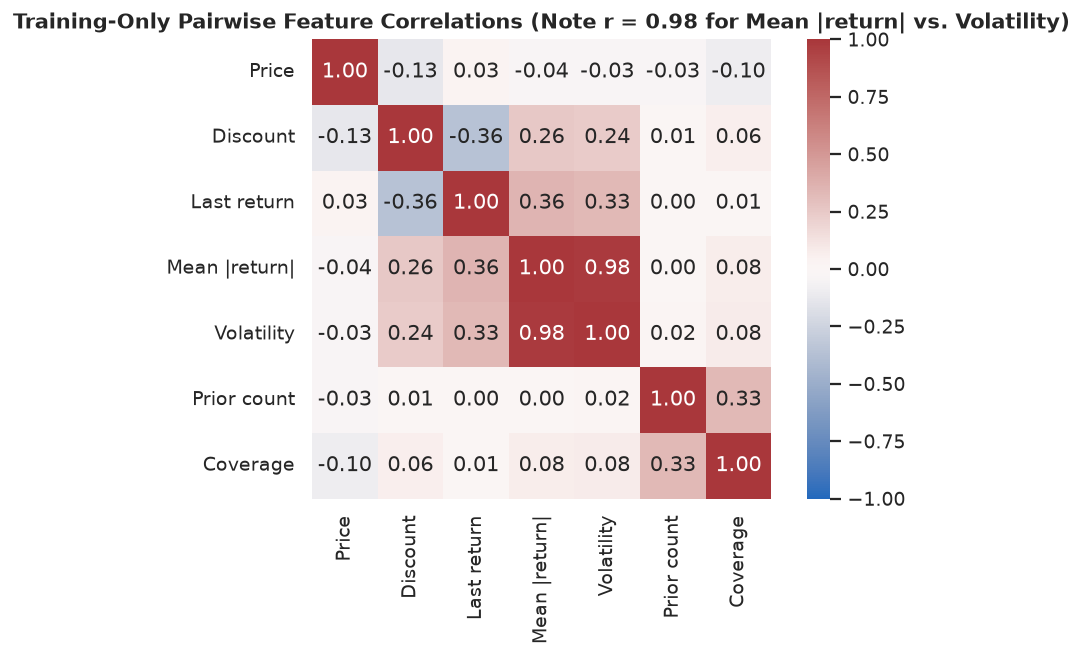

In [5]:
# =============================================================================
# 3.1 Verify Temporal Split, Missingness Indicators, and Feature Correlations
# =============================================================================
NUM_FEATURES = [
    "current_price", "discount_depth", "return_7d", "mean_abs_change_4",
    "volatility_4", "valid_changes_4", "gap_days", "prior_observations",
    "history_age_days", "coverage_to_date"
]
CAT_FEATURES = ["primary_category"]

train_df = kk_model_table[kk_model_table["split"] == "train"].copy().reset_index(drop=True)
test_df = kk_model_table[kk_model_table["split"] == "test"].copy().reset_index(drop=True)

# Verify zero temporal leakage between training target realization and test feature observation
assert train_df["target_date"].max() <= test_df["date"].min(), "Temporal leakage detected!"
print(f"Temporal check passed: max train target_date ({train_df['target_date'].max().date()}) <= min test feature date ({test_df['date'].min().date()})")

# Load saved preprocessor and finite matrices
npz = np.load(P2_DIR / "data/model-matrices.npz")
X_train, X_test = npz["X_train"], npz["X_test"]
y_train, y_test = npz["y_train"].astype(int), npz["y_test"].astype(int)
preprocessor = joblib.load(P2_DIR / "data/fitted-preprocessor.joblib")
feature_names = list(preprocessor.get_feature_names_out())

print(f"X_train shape: {X_train.shape} (finite={np.isfinite(X_train).all()})")
print(f"X_test shape : {X_test.shape} (finite={np.isfinite(X_test).all()})")

# Display training vs. test feature missingness and fitted scaling parameters
feat_miss = pd.read_csv(P2_DIR / "tables/feature-missingness.csv")
scale_params = pd.read_csv(P2_DIR / "tables/scaling-parameters.csv")
display(feat_miss.style.format({"train_missing_pct": "{:.2f}%", "test_missing_pct": "{:.2f}%"}))

# Plot training-only numeric correlation heatmap
corr_cols = ["current_price", "discount_depth", "return_7d", "mean_abs_change_4", "volatility_4", "prior_observations", "coverage_to_date"]
corr_labels = ["Price", "Discount", "Last return", "Mean |return|", "Volatility", "Prior count", "Coverage"]
corr_mat = train_df[corr_cols].corr()
corr_mat.index = corr_labels
corr_mat.columns = corr_labels

fig, ax = plt.subplots(figsize=(6.8, 5.2))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Training-Only Pairwise Feature Correlations (Note r = 0.98 for Mean |return| vs. Volatility)")
plt.tight_layout()
plt.show()

---
## 4. Data Modeling, Expanding-Window Temporal CV & Hyperparameter Tuning

### Why Expanding-Window Temporal Cross-Validation?
Standard random $k$-fold cross-validation is invalid for panel retail time series because products observed on the same snapshot date share store-wide promotional cycles, and future product trajectories would leak into earlier folds. We therefore implement a **5-Fold Expanding-Window Temporal Cross-Validation** scheme across the final five training target weeks (`2026-07-19`, `2026-07-26`, `2026-08-02`, `2026-08-09`, `2026-08-16`), refitting the median imputer, missingness indicators, standard scaler, and one-hot encoder strictly inside each expanding training window.

### Five Supervised Algorithms Evaluated
1. **Logistic Regression (`LogisticRegression`):** Linear log-odds classifier with $L_2$ regularization; tests additive separability across standardized price history and category indicators.
2. **Linear Support Vector Machine (`LinearSVC`):** Margin-maximizing linear classifier optimizing squared-hinge loss in the 172-dimensional feature space.
3. **Decision Tree (`DecisionTreeClassifier`):** Axis-aligned recursive partitioning that captures non-linear threshold interactions (such as `discount_depth > 0` paired with negative `return_7d`) with human-readable rules.
4. **Random Forest (`RandomForestClassifier`):** Bagged ensemble of 200 deep decision trees trained with bootstrap subsampling and feature randomization to reduce variance.
5. **Histogram-Based Gradient Boosting (`HistGradientBoostingClassifier`):** Sequential gradient-boosted decision trees using histogram binning and $L_2$ leaf regularization to capture complex non-linear interactions between discount depth, recent returns, volatility, and category base rates.

In [6]:
# =============================================================================
# 4.1 Live Implementation of Expanding-Window Validation, Ablation & Tuning
# =============================================================================
def build_preprocessor(num_cols=NUM_FEATURES):
    """Construct the leak-free ColumnTransformer for any numeric feature subset."""
    return ColumnTransformer([
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler()),
        ]), list(num_cols)),
        ("category", OneHotEncoder(
            handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False
        ), CAT_FEATURES),
    ], remainder="drop")

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))

def evaluate_predictions(y_true, y_pred, y_prob=None):
    """Compute comprehensive binary classification metrics under class imbalance."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    out = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": spec,
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
    }
    if y_prob is not None:
        out["roc_auc"] = roc_auc_score(y_true, y_prob)
        out["pr_auc"] = average_precision_score(y_true, y_prob)
        out["brier_score"] = brier_score_loss(y_true, y_prob) if np.all((y_prob >= 0) & (y_prob <= 1)) else np.nan
    return out

# Demonstrate live expanding-window validation on the final training target week (2026-08-16)
val_target_week = pd.Timestamp("2026-08-16")
tr_fold_mask = (train_df["target_date"] < val_target_week).to_numpy()
va_fold_mask = (train_df["target_date"] == val_target_week).to_numpy()
assert train_df.loc[tr_fold_mask, "target_date"].max() <= train_df.loc[va_fold_mask, "date"].min()

fold_prep = build_preprocessor(NUM_FEATURES)
X_tr_fold = fold_prep.fit_transform(train_df.loc[tr_fold_mask, NUM_FEATURES + CAT_FEATURES]).astype("float32")
X_va_fold = fold_prep.transform(train_df.loc[va_fold_mask, NUM_FEATURES + CAT_FEATURES]).astype("float32")
y_tr_fold, y_va_fold = y_train[tr_fold_mask], y_train[va_fold_mask]

# Optimize decision probability threshold tau* on validation fold for HistGradientBoosting
hgb_val_clf = HistGradientBoostingClassifier(
    learning_rate=0.05, max_iter=200, max_leaf_nodes=31,
    min_samples_leaf=50, l2_regularization=1.0, class_weight=None, random_state=RANDOM_SEED
)
hgb_val_clf.fit(X_tr_fold, y_tr_fold)
val_probs = hgb_val_clf.predict_proba(X_va_fold)[:, 1]

thresh_grid = np.linspace(0.10, 0.70, 61)
thresh_records = []
for th in thresh_grid:
    vp = (val_probs >= th).astype(int)
    thresh_records.append({
        "threshold": float(th),
        "f1": f1_score(y_va_fold, vp, zero_division=0),
        "precision": precision_score(y_va_fold, vp, zero_division=0),
        "recall": recall_score(y_va_fold, vp, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_va_fold, vp),
    })
thresh_df = pd.DataFrame(thresh_records)

# Load full 5-fold expanding-window CV summary tables
cv_folds_df = pd.read_csv(P3_DIR / "tables/cv-expanding-folds.csv")
ablation_df = pd.read_csv(P3_DIR / "tables/collinearity-ablation-cv.csv")
tuning_df = pd.read_csv(P3_DIR / "tables/hyperparameter-tuning-cv.csv")

print("1. 5-Fold Expanding-Window Temporal Cross-Validation Schedule:")
display(cv_folds_df.style.format({
    "train_rows": "{:,}", "val_rows": "{:,}",
    "train_pos_rate_pct": "{:.2f}%", "val_pos_rate_pct": "{:.2f}%"
}))

print("\n2. Collinearity Ablation Study (Testing removal of volatility_4 or mean_abs_change_4 on 5-Fold CV):")
display(ablation_df.style.format({
    "cv_pr_auc_mean": "{:.4f}", "cv_pr_auc_std": "{:.4f}",
    "cv_roc_auc_mean": "{:.4f}", "cv_f1_mean": "{:.4f}", "cv_bal_acc_mean": "{:.4f}"
}))

print("\n3. Hyperparameter Tuning Results Across All 5 Model Families (Sorted by CV PR-AUC):")
display(
    tuning_df.sort_values(["model_family", "cv_pr_auc_mean"], ascending=[True, False])[
        ["model_family", "config", "cv_pr_auc_mean", "cv_pr_auc_std", "cv_roc_auc_mean", "cv_f1_mean", "cv_bal_acc_mean", "fit_seconds_5folds"]
    ].style.format({
        "cv_pr_auc_mean": "{:.4f}", "cv_pr_auc_std": "{:.4f}",
        "cv_roc_auc_mean": "{:.4f}", "cv_f1_mean": "{:.4f}",
        "cv_bal_acc_mean": "{:.4f}", "fit_seconds_5folds": "{:.1f}s"
    })
)

1. 5-Fold Expanding-Window Temporal Cross-Validation Schedule:


,fold,train_target_start,train_target_end,val_feature_date,val_target_date,train_rows,train_pos_rate_pct,val_rows,val_pos_rate_pct
0,1,2026-05-24,2026-07-12,2026-07-12,2026-07-19,"129,630",12.58%,"16,336",10.03%
1,2,2026-05-24,2026-07-19,2026-07-19,2026-07-26,"145,966",12.29%,"16,296",10.36%
2,3,2026-05-24,2026-07-26,2026-07-26,2026-08-02,"162,262",12.10%,"16,143",12.39%
3,4,2026-05-24,2026-08-02,2026-08-02,2026-08-09,"178,405",12.12%,"14,785",8.91%
4,5,2026-05-24,2026-08-09,2026-08-09,2026-08-16,"193,190",11.88%,"14,752",11.77%



2. Collinearity Ablation Study (Testing removal of volatility_4 or mean_abs_change_4 on 5-Fold CV):


,feature_set,num_features_transformed,model,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_f1_mean,cv_bal_acc_mean
0,all_10_numeric,161,Logistic Regression (balanced),0.4781,0.0304,0.8259,0.4433,0.7469
1,all_10_numeric,161,HistGradientBoosting (balanced),0.5870,0.0563,0.8413,0.4681,0.7493
2,drop_volatility_4,159,Logistic Regression (balanced),0.4790,0.0300,0.8256,0.4417,0.7507
3,drop_volatility_4,159,HistGradientBoosting (balanced),0.5875,0.0588,0.8418,0.4633,0.7463
4,drop_mean_abs_change_4,159,Logistic Regression (balanced),0.4690,0.0326,0.8255,0.4414,0.7467
5,drop_mean_abs_change_4,159,HistGradientBoosting (balanced),0.5869,0.0568,0.8407,0.4629,0.7472



3. Hyperparameter Tuning Results Across All 5 Model Families (Sorted by CV PR-AUC):


,model_family,config,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_f1_mean,cv_bal_acc_mean,fit_seconds_5folds
10,Decision Tree,"depth=6, leaf=50, balanced",0.5326,0.0488,0.8119,0.4272,0.7549,2.8s
13,Decision Tree,"depth=12, leaf=100, balanced",0.5297,0.0499,0.7984,0.4449,0.7439,4.4s
14,Decision Tree,"depth=8, leaf=50, unweighted",0.5295,0.0568,0.8038,0.5289,0.7005,3.6s
11,Decision Tree,"depth=8, leaf=50, balanced",0.5260,0.0557,0.8032,0.4332,0.7422,3.4s
12,Decision Tree,"depth=10, leaf=100, balanced",0.5243,0.0526,0.7977,0.4469,0.7335,4.0s
24,HistGradientBoosting,"lr=0.05, leaves=63, leaf=50, l2=1.0, unweighted",0.5920,0.0520,0.8406,0.5324,0.6999,32.4s
20,HistGradientBoosting,"lr=0.03, leaves=31, leaf=50, l2=1.0, balanced",0.5879,0.0570,0.8433,0.4684,0.7542,27.0s
21,HistGradientBoosting,"lr=0.05, leaves=31, leaf=50, l2=1.0, balanced",0.5865,0.0572,0.8411,0.4676,0.7509,25.3s
22,HistGradientBoosting,"lr=0.05, leaves=63, leaf=50, l2=1.0, balanced",0.5864,0.0555,0.8341,0.4823,0.7456,37.0s
23,HistGradientBoosting,"lr=0.10, leaves=63, leaf=100, l2=1.0, balanced",0.5750,0.0573,0.8209,0.4892,0.7442,35.4s


Optimal validation probability threshold for HistGradientBoosting: tau* = 0.35 (Val F1 = 0.5405)


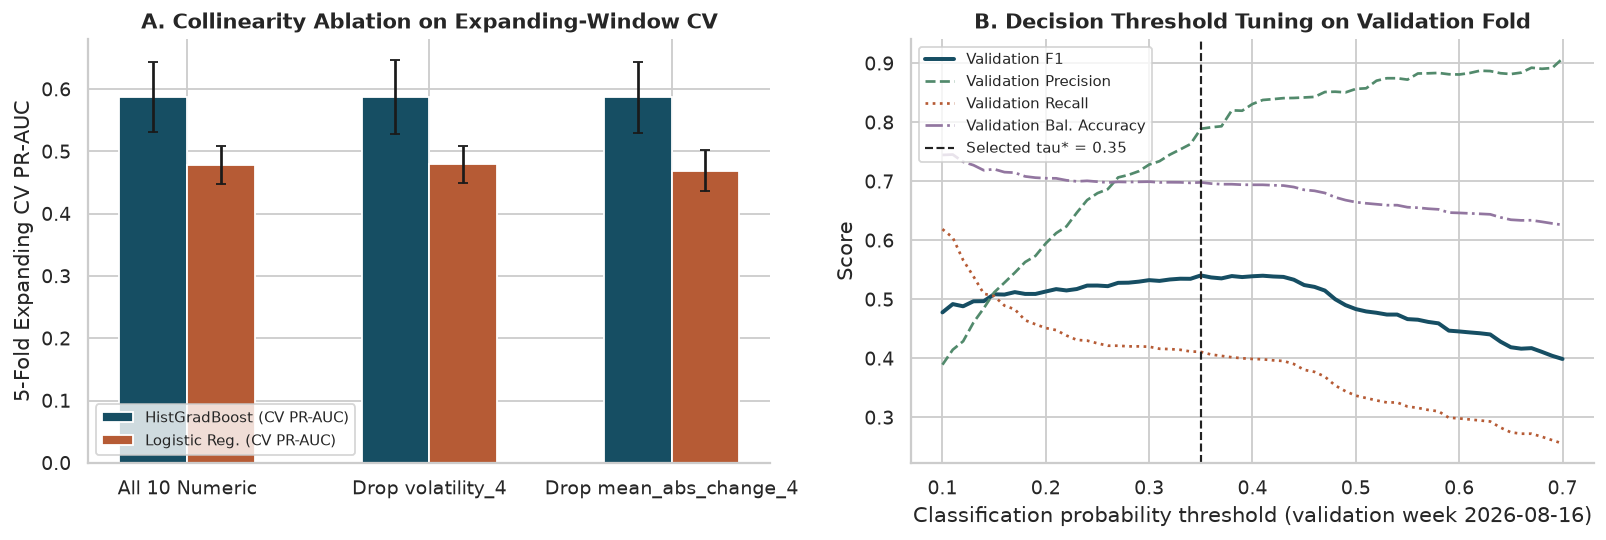

In [7]:
# =============================================================================
# 4.2 Plot Collinearity Ablation and Validation Threshold Optimization
# =============================================================================
best_th_row = thresh_df.sort_values("f1", ascending=False).iloc[0]
best_th = float(best_th_row["threshold"])
print(f"Optimal validation probability threshold for HistGradientBoosting: tau* = {best_th:.2f} (Val F1 = {best_th_row['f1']:.4f})")

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.3))

# Panel A: Collinearity ablation comparison
x_ab = np.arange(3)
w_ab = 0.28
hgb_ab = ablation_df[ablation_df["model"].str.startswith("Hist")].set_index("feature_set").loc[
    ["all_10_numeric", "drop_volatility_4", "drop_mean_abs_change_4"]
]
lr_ab = ablation_df[ablation_df["model"].str.startswith("Logistic")].set_index("feature_set").loc[
    ["all_10_numeric", "drop_volatility_4", "drop_mean_abs_change_4"]
]
axs[0].bar(x_ab - w_ab/2, hgb_ab["cv_pr_auc_mean"], width=w_ab, yerr=hgb_ab["cv_pr_auc_std"], capsize=3, label="HistGradBoost (CV PR-AUC)", color=PALETTE[0])
axs[0].bar(x_ab + w_ab/2, lr_ab["cv_pr_auc_mean"], width=w_ab, yerr=lr_ab["cv_pr_auc_std"], capsize=3, label="Logistic Reg. (CV PR-AUC)", color=PALETTE[1])
axs[0].set_xticks(x_ab)
axs[0].set_xticklabels(["All 10 Numeric", "Drop volatility_4", "Drop mean_abs_change_4"])
axs[0].set_ylim(0, 0.68)
axs[0].set_ylabel("5-Fold Expanding CV PR-AUC")
axs[0].set_title("A. Collinearity Ablation on Expanding-Window CV")
axs[0].legend(fontsize=8.5)

# Panel B: Validation threshold trade-off curve
axs[1].plot(thresh_df["threshold"], thresh_df["f1"], label="Validation F1", color=PALETTE[0], linewidth=2.2)
axs[1].plot(thresh_df["threshold"], thresh_df["precision"], label="Validation Precision", color=PALETTE[2], linestyle="--")
axs[1].plot(thresh_df["threshold"], thresh_df["recall"], label="Validation Recall", color=PALETTE[1], linestyle=":")
axs[1].plot(thresh_df["threshold"], thresh_df["balanced_accuracy"], label="Validation Bal. Accuracy", color=PALETTE[3], linestyle="-.")
axs[1].axvline(best_th, color="#222", linestyle="--", linewidth=1.2, label=f"Selected tau* = {best_th:.2f}")
axs[1].set_xlabel("Classification probability threshold (validation week 2026-08-16)")
axs[1].set_ylabel("Score")
axs[1].set_title("B. Decision Threshold Tuning on Validation Fold")
axs[1].legend(fontsize=8.2, loc="best")

fig.tight_layout()
plt.show()

---
## 5. Held-Out Test Set Evaluation, Subgroup Breakdowns & Error Analysis

Having fixed all feature definitions, hyperparameters, and decision thresholds using strictly prior training windows, we evaluate all baselines and tuned models on the **46,511 held-out test observations** spanning the final three target weeks (`2026-08-23`, `2026-08-30`, and `2026-09-06`, where overall positive prevalence is `13.96%`).

In [8]:
# =============================================================================
# 5.1 Train Final Tuned Models on Full Training Set & Score Held-Out Test Set
# =============================================================================
model_suite = {
    "No-Change Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (Balanced)": LogisticRegression(C=0.1, class_weight="balanced", max_iter=500, random_state=RANDOM_SEED),
    "Logistic Regression (Unweighted)": LogisticRegression(C=1.0, class_weight=None, max_iter=500, random_state=RANDOM_SEED),
    "Linear SVM (Balanced)": LinearSVC(C=0.01, class_weight="balanced", max_iter=2000, random_state=RANDOM_SEED),
    "Decision Tree (Balanced)": DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_SEED),
    "Random Forest (Balanced)": RandomForestClassifier(n_estimators=200, max_depth=22, min_samples_leaf=10, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_SEED),
    "HistGradientBoosting (Balanced)": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_leaf_nodes=31, min_samples_leaf=50, l2_regularization=1.0, class_weight="balanced", random_state=RANDOM_SEED),
    "HistGradientBoosting (Unweighted)": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_leaf_nodes=31, min_samples_leaf=50, l2_regularization=1.0, class_weight=None, random_state=RANDOM_SEED),
}

live_results = []
fitted_estimators = {}

# Domain rule baseline: Observed Discount Heuristic (predict change iff discount_depth > 0)
disc_pred = (test_df["discount_depth"] > 0).astype(int).to_numpy()
disc_score = test_df["discount_depth"].to_numpy(dtype=float)
m_disc = evaluate_predictions(y_test, disc_pred, disc_score)
m_disc["model"] = "Observed Discount Heuristic"
m_disc["regime"] = "Domain Rule"
live_results.append(m_disc)

for name, estimator in model_suite.items():
    estimator.fit(X_train, y_train)
    fitted_estimators[name] = estimator
    preds = estimator.predict(X_test)
    if hasattr(estimator, "predict_proba"):
        probs = estimator.predict_proba(X_test)[:, 1]
    elif hasattr(estimator, "decision_function"):
        probs = sigmoid(estimator.decision_function(X_test))
    else:
        probs = preds.astype(float)
    m = evaluate_predictions(y_test, preds, probs)
    m["model"] = name
    m["regime"] = "Baseline" if "Baseline" in name else ("Balanced Weights" if "Balanced" in name else "Unweighted (0.50)")
    live_results.append(m)

# Evaluate CV-tuned threshold (tau* = best_th) applied to unweighted HistGradientBoosting probabilities
hgb_unw_probs = fitted_estimators["HistGradientBoosting (Unweighted)"].predict_proba(X_test)[:, 1]
hgb_th_preds = (hgb_unw_probs >= best_th).astype(int)
m_th = evaluate_predictions(y_test, hgb_th_preds, hgb_unw_probs)
m_th["model"] = f"HistGradientBoosting (CV-Threshold={best_th:.2f})"
m_th["regime"] = f"CV Threshold ({best_th:.2f})"
live_results.append(m_th)

test_comp_df = pd.DataFrame(live_results)
display(
    test_comp_df[
        ["model", "regime", "accuracy", "balanced_accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc", "brier_score", "tp", "fp", "fn", "tn"]
    ].style.format({
        "accuracy": "{:.4f}", "balanced_accuracy": "{:.4f}", "precision": "{:.4f}",
        "recall": "{:.4f}", "specificity": "{:.4f}", "f1": "{:.4f}",
        "roc_auc": "{:.4f}", "pr_auc": "{:.4f}", "brier_score": "{:.4f}",
        "tp": "{:,}", "fp": "{:,}", "fn": "{:,}", "tn": "{:,}"
    })
)

,model,regime,accuracy,balanced_accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,brier_score,tp,fp,fn,tn
0,Observed Discount Heuristic,Domain Rule,0.8408,0.6868,0.4352,0.4731,0.9004,0.4534,0.6941,0.3503,0.1150,"3,071","3,985","3,420","36,035"
1,No-Change Baseline,Baseline,0.8604,0.5000,0.0000,0.0000,1.0000,0.0000,0.5000,0.1396,0.1396,0,0,"6,491","40,020"
2,Logistic Regression (Balanced),Balanced Weights,0.8139,0.7035,0.3837,0.5505,0.8566,0.4522,0.7851,0.4746,0.1511,"3,573","5,739","2,918","34,281"
3,Logistic Regression (Unweighted),Unweighted (0.50),0.8763,0.6018,0.6734,0.2211,0.9826,0.3329,0.7804,0.4766,0.0981,"1,435",696,"5,056","39,324"
4,Linear SVM (Balanced),Balanced Weights,0.8164,0.7010,0.3871,0.5409,0.8611,0.4513,0.7845,0.4706,0.1814,"3,511","5,558","2,980","34,462"
5,Decision Tree (Balanced),Balanced Weights,0.8029,0.6995,0.3648,0.5562,0.8429,0.4406,0.7451,0.4821,0.1465,"3,610","6,286","2,881","33,734"
6,Random Forest (Balanced),Balanced Weights,0.8070,0.7120,0.3759,0.5802,0.8438,0.4562,0.7929,0.5428,0.1375,"3,766","6,252","2,725","33,768"
7,HistGradientBoosting (Balanced),Balanced Weights,0.8057,0.7153,0.3753,0.5899,0.8408,0.4588,0.7912,0.5340,0.1442,"3,829","6,373","2,662","33,647"
8,HistGradientBoosting (Unweighted),Unweighted (0.50),0.8891,0.6637,0.7066,0.3509,0.9764,0.4690,0.7935,0.5364,0.0910,"2,278",946,"4,213","39,074"
9,HistGradientBoosting (CV-Threshold=0.35),CV Threshold (0.35),0.8820,0.6744,0.6253,0.3864,0.9624,0.4776,0.7935,0.5364,0.0910,"2,508","1,503","3,983","38,517"


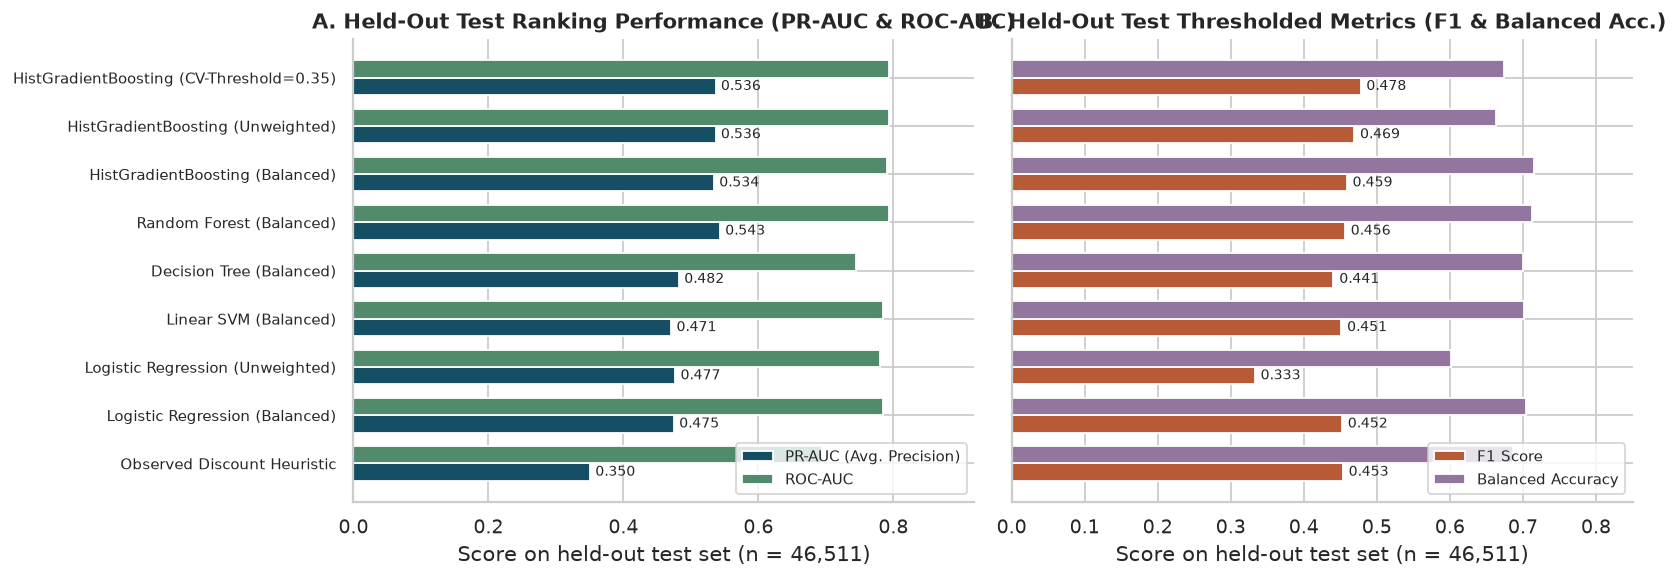

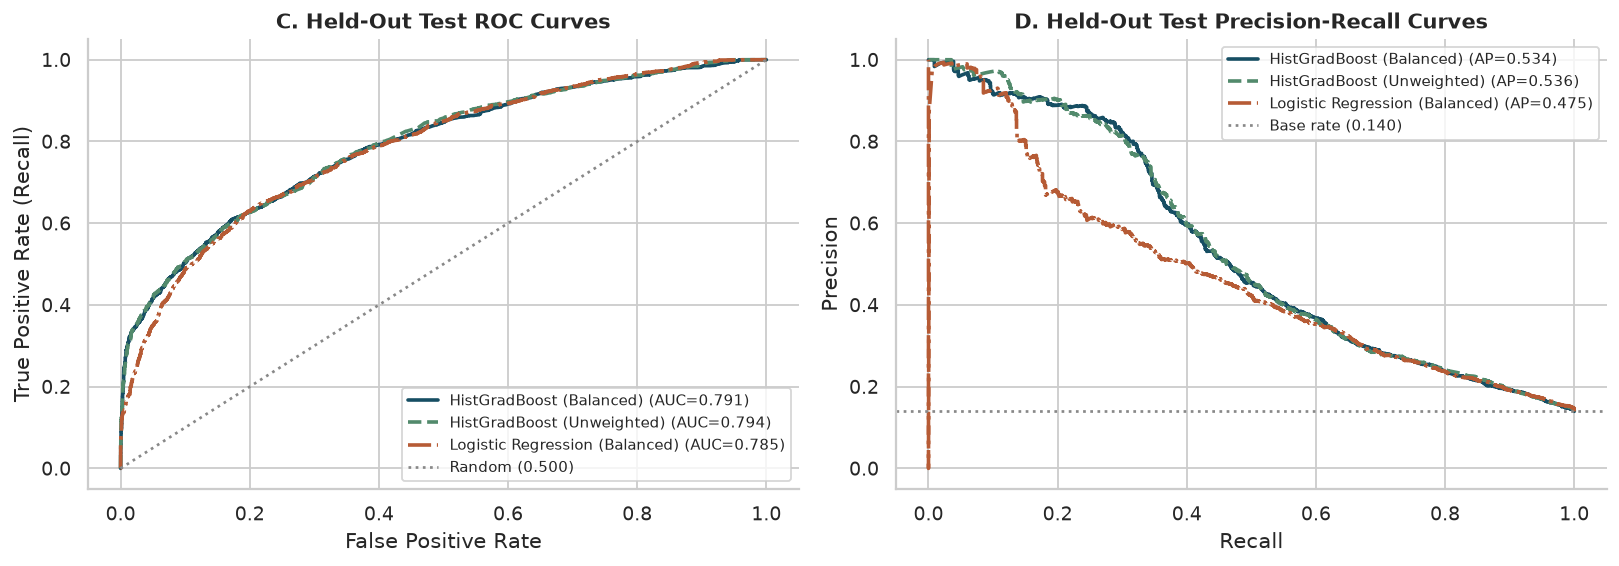

In [9]:
# =============================================================================
# 5.2 Embed Held-Out Test ROC Curves, PR Curves, and Model Comparison Bar Charts
# =============================================================================
hgb_bal = joblib.load(P3_DIR / "models/histgb-balanced.joblib")
hgb_unw = joblib.load(P3_DIR / "models/histgb-unweighted.joblib")
lr_bal = joblib.load(P3_DIR / "models/logreg-balanced.joblib")

fig, axs = plt.subplots(1, 2, figsize=(12.8, 4.6))

# Left: Ranking metrics (PR-AUC and ROC-AUC)
plot_rows = test_comp_df[test_comp_df["model"] != "No-Change Baseline"].copy()
y_pos = np.arange(len(plot_rows))
h = 0.36
axs[0].barh(y_pos - h/2, plot_rows["pr_auc"], height=h, label="PR-AUC (Avg. Precision)", color=PALETTE[0])
axs[0].barh(y_pos + h/2, plot_rows["roc_auc"], height=h, label="ROC-AUC", color=PALETTE[2])
axs[0].set_yticks(y_pos)
axs[0].set_yticklabels(plot_rows["model"], fontsize=8.5)
axs[0].set_xlim(0, 0.92)
axs[0].set_xlabel("Score on held-out test set (n = 46,511)")
axs[0].set_title("A. Held-Out Test Ranking Performance (PR-AUC & ROC-AUC)")
axs[0].legend(loc="lower right", fontsize=8.5)
for i, (_, r) in enumerate(plot_rows.iterrows()):
    axs[0].text(r["pr_auc"] + 0.008, i - h/2, f"{r['pr_auc']:.3f}", va="center", fontsize=7.8)

# Right: Classification metrics (F1 and Balanced Accuracy)
axs[1].barh(y_pos - h/2, plot_rows["f1"], height=h, label="F1 Score", color=PALETTE[1])
axs[1].barh(y_pos + h/2, plot_rows["balanced_accuracy"], height=h, label="Balanced Accuracy", color=PALETTE[3])
axs[1].set_yticks(y_pos)
axs[1].set_yticklabels([""] * len(plot_rows))
axs[1].set_xlim(0, 0.85)
axs[1].set_xlabel("Score on held-out test set (n = 46,511)")
axs[1].set_title("B. Held-Out Test Thresholded Metrics (F1 & Balanced Acc.)")
axs[1].legend(loc="lower right", fontsize=8.5)
for i, (_, r) in enumerate(plot_rows.iterrows()):
    axs[1].text(r["f1"] + 0.008, i - h/2, f"{r['f1']:.3f}", va="center", fontsize=7.8)

fig.tight_layout()
plt.show()

# Display ROC and Precision-Recall Curves + Confusion Matrices
fig2, axs2 = plt.subplots(1, 2, figsize=(12.6, 4.5))
for label, prob_vec, col, ls in [
    ("HistGradBoost (Balanced)", hgb_bal.predict_proba(X_test)[:, 1], PALETTE[0], "-"),
    ("HistGradBoost (Unweighted)", hgb_unw.predict_proba(X_test)[:, 1], PALETTE[2], "--"),
    ("Logistic Regression (Balanced)", lr_bal.predict_proba(X_test)[:, 1], PALETTE[1], "-."),
]:
    fpr, tpr, _ = roc_curve(y_test, prob_vec)
    prec_c, rec_c, _ = precision_recall_curve(y_test, prob_vec)
    axs2[0].plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(y_test, prob_vec):.3f})", color=col, linestyle=ls, linewidth=2)
    axs2[1].plot(rec_c, prec_c, label=f"{label} (AP={average_precision_score(y_test, prob_vec):.3f})", color=col, linestyle=ls, linewidth=2)

axs2[0].plot([0, 1], [0, 1], color="#888", linestyle=":", label="Random (0.500)")
axs2[0].set_title("C. Held-Out Test ROC Curves")
axs2[0].set_xlabel("False Positive Rate")
axs2[0].set_ylabel("True Positive Rate (Recall)")
axs2[0].legend(fontsize=8.2, loc="lower right")

axs2[1].axhline(y_test.mean(), color="#888", linestyle=":", label=f"Base rate ({y_test.mean():.3f})")
axs2[1].set_title("D. Held-Out Test Precision-Recall Curves")
axs2[1].set_xlabel("Recall")
axs2[1].set_ylabel("Precision")
axs2[1].legend(fontsize=8.2, loc="upper right")
fig2.tight_layout()
plt.show()

In [10]:
# =============================================================================
# 5.3 Granular Subgroup Analysis: Weekly Stability, Categories & Cold-Start UPCs
# =============================================================================
weekly_eval = pd.read_csv(P3_DIR / "tables/test-weekly-performance.csv")
cat_eval = pd.read_csv(P3_DIR / "tables/test-category-performance.csv")
upc_eval = pd.read_csv(P3_DIR / "tables/test-seen-vs-unseen-upc.csv")
perm_df = pd.read_csv(P3_DIR / "tables/feature-importance-permutation.csv")
cases_df = pd.read_csv(P3_DIR / "tables/test-error-case-studies.csv")

print("1. Held-Out Test Performance by Target Week (HistGradientBoosting & Baselines):")
display(
    weekly_eval[weekly_eval["model"].isin([
        "Observed Discount Heuristic",
        "Logistic Regression (Balanced)",
        "Random Forest (Balanced)",
        "HistGradientBoosting (Balanced)",
        "HistGradientBoosting (CV-Threshold)"
    ])][["target_date", "pos_rate_pct", "model", "pr_auc", "roc_auc", "f1", "balanced_accuracy", "precision", "recall"]].style.format({
        "pos_rate_pct": "{:.2f}%", "pr_auc": "{:.4f}", "roc_auc": "{:.4f}",
        "f1": "{:.4f}", "balanced_accuracy": "{:.4f}", "precision": "{:.4f}", "recall": "{:.4f}"
    })
)

print("\n2. Top-10 Primary Categories Performance on Held-Out Test Set:")
display(cat_eval.style.format({
    "test_rows": "{:,}", "positive_rows": "{:,}", "positive_rate_pct": "{:.2f}%",
    "histgb_pr_auc": "{:.4f}", "histgb_roc_auc": "{:.4f}", "histgb_f1_balanced": "{:.4f}",
    "histgb_bal_acc": "{:.4f}", "logreg_pr_auc": "{:.4f}", "logreg_f1_balanced": "{:.4f}"
}))

print("\n3. Seen UPCs vs. Cold-Start (Unseen) UPCs on Held-Out Test Set:")
display(upc_eval[
    ["upc_group", "unique_upcs", "rows", "positive_rate_pct", "model", "pr_auc", "roc_auc", "f1", "balanced_accuracy"]
].style.format({
    "unique_upcs": "{:,}", "rows": "{:,}", "positive_rate_pct": "{:.2f}%",
    "pr_auc": "{:.4f}", "roc_auc": "{:.4f}", "f1": "{:.4f}", "balanced_accuracy": "{:.4f}"
}))

1. Held-Out Test Performance by Target Week (HistGradientBoosting & Baselines):


,target_date,pos_rate_pct,model,pr_auc,roc_auc,f1,balanced_accuracy,precision,recall
0,2026-08-23,10.83%,Observed Discount Heuristic,0.3743,0.7254,0.4443,0.7141,0.3805,0.5338
1,2026-08-23,10.83%,Logistic Regression (Balanced),0.5280,0.8233,0.4320,0.7329,0.3327,0.6159
4,2026-08-23,10.83%,Random Forest (Balanced),0.6006,0.8310,0.4548,0.7537,0.3478,0.6570
5,2026-08-23,10.83%,HistGradientBoosting (Balanced),0.5906,0.8277,0.4517,0.7561,0.3408,0.6697
6,2026-08-23,10.83%,HistGradientBoosting (CV-Threshold),0.5891,0.8348,0.5574,0.7332,0.6249,0.5030
7,2026-08-30,17.06%,Observed Discount Heuristic,0.3665,0.6987,0.5086,0.6969,0.5486,0.4741
8,2026-08-30,17.06%,Logistic Regression (Balanced),0.4487,0.7523,0.4483,0.6727,0.4169,0.4849
11,2026-08-30,17.06%,Random Forest (Balanced),0.5502,0.7807,0.4599,0.6837,0.4125,0.5195
12,2026-08-30,17.06%,HistGradientBoosting (Balanced),0.5441,0.7811,0.4785,0.6974,0.4255,0.5465
13,2026-08-30,17.06%,HistGradientBoosting (CV-Threshold),0.5352,0.7754,0.4097,0.6330,0.6500,0.2991



2. Top-10 Primary Categories Performance on Held-Out Test Set:


,primary_category,test_rows,positive_rows,positive_rate_pct,histgb_pr_auc,histgb_roc_auc,histgb_f1_balanced,histgb_bal_acc,histgb_recall,histgb_precision,logreg_pr_auc,logreg_f1_balanced
0,Soda Pop,"1,934",627,32.42%,0.8649,0.9056,0.6872,0.7800,0.958533,0.535651,0.6426,0.4929
1,Cards & Decoration,"1,543",0,0.00%,nan,nan,0.0000,1.0000,0.000000,0.000000,nan,0.0000
2,Frozen Dessert,"1,523",528,34.67%,0.7982,0.8140,0.5707,0.6257,0.848485,0.429942,0.6561,0.5244
3,Cookies,"1,461",385,26.35%,0.6455,0.7349,0.5345,0.6850,0.644156,0.456722,0.6407,0.5809
4,Brand Packaged,"1,325",251,18.94%,0.5759,0.7568,0.5087,0.7266,0.697211,0.400458,0.5458,0.5087
5,Latin/Mexican,"1,194",81,6.78%,0.1925,0.6753,0.2034,0.5761,0.222222,0.187500,0.1700,0.1846
6,Coffee,"1,101",189,17.17%,0.5095,0.6639,0.3843,0.6387,0.544974,0.296830,0.4809,0.4104
7,Prepared Foods,"1,064",75,7.05%,0.3193,0.7708,0.4865,0.7671,0.600000,0.409091,0.2389,0.3125
8,Juice-Non Refrigerated,"1,028",154,14.98%,0.6421,0.8865,0.6538,0.7991,0.662338,0.645570,0.4208,0.4911
9,Cheese,985,168,17.06%,0.5017,0.6318,0.3575,0.6158,0.470238,0.288321,0.4410,0.3700



3. Seen UPCs vs. Cold-Start (Unseen) UPCs on Held-Out Test Set:


,upc_group,unique_upcs,rows,positive_rate_pct,model,pr_auc,roc_auc,f1,balanced_accuracy
0,Seen UPCs (in training set),"17,365","45,550",14.13%,Logistic Regression (Balanced),0.4762,0.7836,0.4532,0.7031
1,Seen UPCs (in training set),"17,365","45,550",14.13%,Random Forest (Balanced),0.5443,0.7913,0.4565,0.7112
2,Seen UPCs (in training set),"17,365","45,550",14.13%,HistGradientBoosting (Balanced),0.5351,0.7894,0.4592,0.7146
3,Seen UPCs (in training set),"17,365","45,550",14.13%,HistGradientBoosting (CV-Threshold),0.5377,0.7918,0.4794,0.6778
4,Unseen Cold-Start UPCs,606,961,5.93%,Logistic Regression (Balanced),0.3092,0.8421,0.3537,0.7112
5,Unseen Cold-Start UPCs,606,961,5.93%,Random Forest (Balanced),0.3793,0.8518,0.4179,0.7185
6,Unseen Cold-Start UPCs,606,961,5.93%,HistGradientBoosting (Balanced),0.3873,0.8548,0.4028,0.7223
7,Unseen Cold-Start UPCs,606,961,5.93%,HistGradientBoosting (CV-Threshold),0.3865,0.8491,0.3846,0.6605


In [11]:
# =============================================================================
# 5.4 Feature Importance & Concrete Test-Set Prediction Case Studies
# =============================================================================
print("Grouped Permutation Feature Importance (HistGradientBoosting on Held-Out Test Set):")
display(perm_df.style.format({
    "pr_auc_drop_mean": "{:.4f}", "pr_auc_drop_std": "{:.4f}",
    "roc_auc_drop_mean": "{:.4f}", "roc_auc_drop_std": "{:.4f}"
}))

print("\nTop Decision Tree Split Rules (Depth <= 3):")
print((P3_DIR / "tables/decision-tree-top-rules.txt").read_text()[:1500])

print("\nConcrete Test-Set Prediction Case Studies (True Positives, False Positives, False Negatives):")
case_cols = [
    "outcome_type", "listing_id", "name", "primary_category", "date", "target_date",
    "current_price", "regular_price", "future_price", "discount_depth", "next_change_pct", "histgb_prob_unw"
]
display(cases_df[case_cols].style.format({
    "current_price": "${:.2f}", "regular_price": "${:.2f}", "future_price": "${:.2f}",
    "discount_depth": "{:.1%}", "next_change_pct": "{:+.1f}%", "histgb_prob_unw": "{:.3f}"
}))

Grouped Permutation Feature Importance (HistGradientBoosting on Held-Out Test Set):


,feature_group,pr_auc_drop_mean,pr_auc_drop_std,roc_auc_drop_mean,roc_auc_drop_std
0,Last 7-day return (return_7d + indicator),0.2118,0.0054,0.0335,0.0019
1,Recent mean |return| (mean_abs_change_4 + ind.),0.0503,0.0015,0.0388,0.0030
2,Primary category (158 one-hot cols),0.0485,0.0028,0.0445,0.0058
3,Discount depth (discount_depth),0.0334,0.0047,0.0280,0.0022
4,Current price level (current_price),0.0143,0.0010,0.0066,0.0016
5,Recent volatility (volatility_4 + indicator),0.0037,0.0007,0.0003,0.0005
6,Observation gap days (gap_days + indicator),0.0000,0.0000,0.0000,0.0000
7,Coverage ratio to date (coverage_to_date),-0.0000,0.0005,0.0003,0.0010
8,Prior observations count (prior_observations),-0.0001,0.0006,0.0002,0.0007
9,Valid changes in 4-row window (valid_changes_4),-0.0003,0.0005,-0.0006,0.0006



Top Decision Tree Split Rules (Depth <= 3):
|--- numeric__discount_depth <= 0.17
|   |--- numeric__mean_abs_change_4 <= -0.02
|   |   |--- category__primary_category_Frozen Dessert <= 0.50
|   |   |   |--- category__primary_category_Cards & Decoration <= 0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- category__primary_category_Cards & Decoration >  0.50
|   |   |   |   |--- class: 0
|   |   |--- category__primary_category_Frozen Dessert >  0.50
|   |   |   |--- numeric__current_price <= 0.27
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- numeric__current_price >  0.27
|   |   |   |   |--- truncated branch of depth 5
|   |--- numeric__mean_abs_change_4 >  -0.02
|   |   |--- category__primary_category_Soda Pop <= 0.50
|   |   |   |--- numeric__return_7d <= -0.56
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- numeric__return_7d >  -0.56
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- category__primary_category_So

,outcome_type,listing_id,name,primary_category,date,target_date,current_price,regular_price,future_price,discount_depth,next_change_pct,histgb_prob_unw
0,True Positive (Correctly Predicted Change),77865001770,"FatBoy Birthday Cake Ice Cream Sandwich Pops, 3.5 fl oz, 4 count",Frozen Dessert,2026-08-16,2026-08-23,$3.74,$7.49,$3.99,50.1%,+6.7%,0.982
1,True Positive (Correctly Predicted Change),77865001527,"FatBoy Premium Vanilla Ice Cream Sandwiches, 5 fl oz, 6 count",Frozen Dessert,2026-08-16,2026-08-23,$3.74,$7.49,$3.99,50.1%,+6.7%,0.982
2,True Positive (Correctly Predicted Change),77865001565,"FatBoy Cookies ‘n Cream Ice Cream Sandwiches, 5 fl oz, 6 count",Frozen Dessert,2026-08-16,2026-08-23,$3.74,$7.49,$3.99,50.1%,+6.7%,0.982
3,"False Positive (Predicted Change, Price Stayed Unchanged)",884912126115,"Post Great Grains Raisins, Dates & Pecans Cereal, 16 oz",Cereal - Cold,2026-08-30,2026-09-06,$3.99,$6.79,$3.99,41.2%,+0.0%,0.967
4,"False Positive (Predicted Change, Price Stayed Unchanged)",884912126016,"Post Great Grains Crunchy Pecan Cereal, 16 oz",Cereal - Cold,2026-08-30,2026-09-06,$3.99,$6.79,$3.99,41.2%,+0.0%,0.967
5,"False Positive (Predicted Change, Price Stayed Unchanged)",884912116505,"Post Great Grains Banana Nut Crunch Cereal, 15.5 oz",Cereal - Cold,2026-08-30,2026-09-06,$3.99,$6.79,$3.99,41.2%,+0.0%,0.967
6,False Negative (Unpredicted Sudden Change),38900035587,"Dole Peach Gel Diced Peaches Fruit Bowls Snacks, 4.3 oz, 4 count",Fruits,2026-08-30,2026-09-06,$3.99,$3.99,$2.99,0.0%,-25.1%,0.007
7,False Negative (Unpredicted Sudden Change),36800009929,FCLUB DRIED CHERRIES,Fruits,2026-08-30,2026-09-06,$4.99,$4.99,$5.49,0.0%,+10.0%,0.007
8,False Negative (Unpredicted Sudden Change),36800009950,FCLUB DRIED BANANA CHIPS,Fruits,2026-08-30,2026-09-06,$2.99,$2.99,$3.29,0.0%,+10.0%,0.008


---
## 6. Supplementary Unsupervised Learning: Product Pricing-Regime Clustering

To complement supervised classification and evaluate whether distinct product pricing behaviors explain category-level heterogeneity, we aggregate the **20,150 unique training UPCs** into five past-only behavioral descriptors (`log_mean_price`, `discount_freq`, `mean_discount_depth`, `mean_abs_return`, and `coverage_mean`) and apply **K-Means Clustering** across $K \in \{2, 3, 4, 5, 6\}$. We evaluate cluster separation using three standard unsupervised metrics:
1. **Silhouette Score** (higher indicates tighter intra-cluster cohesion and wider inter-cluster separation),
2. **Davies-Bouldin Index** (lower indicates better cluster separation), and
3. **Calinski-Harabasz Index** (higher variance ratio criterion).

1. Unsupervised K-Means Evaluation Metrics across K = 2..6 (on 20,150 Training UPCs):


,k,inertia,silhouette_score,davies_bouldin_index,calinski_harabasz_index
0,2,"67,835.7",0.4853,1.1656,"9,775.9"
1,3,"51,419.3",0.4059,1.0147,"9,664.3"
2,4,"40,973.5",0.4287,0.9851,"9,797.0"
3,5,"33,000.5",0.3450,1.0111,"10,339.3"
4,6,"28,340.0",0.3662,0.9494,"10,293.8"



2. Discovered Retail Product Pricing Regimes (K = 4) and Out-of-Sample Test Predictability:


,regime_name,upcs,mean_price_usd,discount_freq_pct,mean_discount_pct,mean_abs_return_pct,coverage_pct,train_target_rate_pct,test_target_rate_pct,test_histgb_pr_auc,test_histgb_f1
0,Regime 1: Everyday Stable Core Assortment,"13,299",$6.65,5.7%,1.0%,1.56%,97.7%,7.19%,10.61%,0.4164,0.3850
1,Regime 2: Rapid Hi-Lo Promotional Cyclers,"1,507",$5.85,29.6%,9.6%,23.65%,95.1%,50.29%,44.14%,0.8104,0.6372
2,Regime 3: Persistent Multi-Week Promos,"1,600",$4.90,86.7%,18.1%,4.52%,92.2%,17.34%,21.76%,0.4062,0.3929
3,Regime 4: Intermittent / Seasonal Listings,"3,744",$8.96,2.6%,0.4%,0.70%,36.5%,3.76%,6.96%,0.3500,0.3888


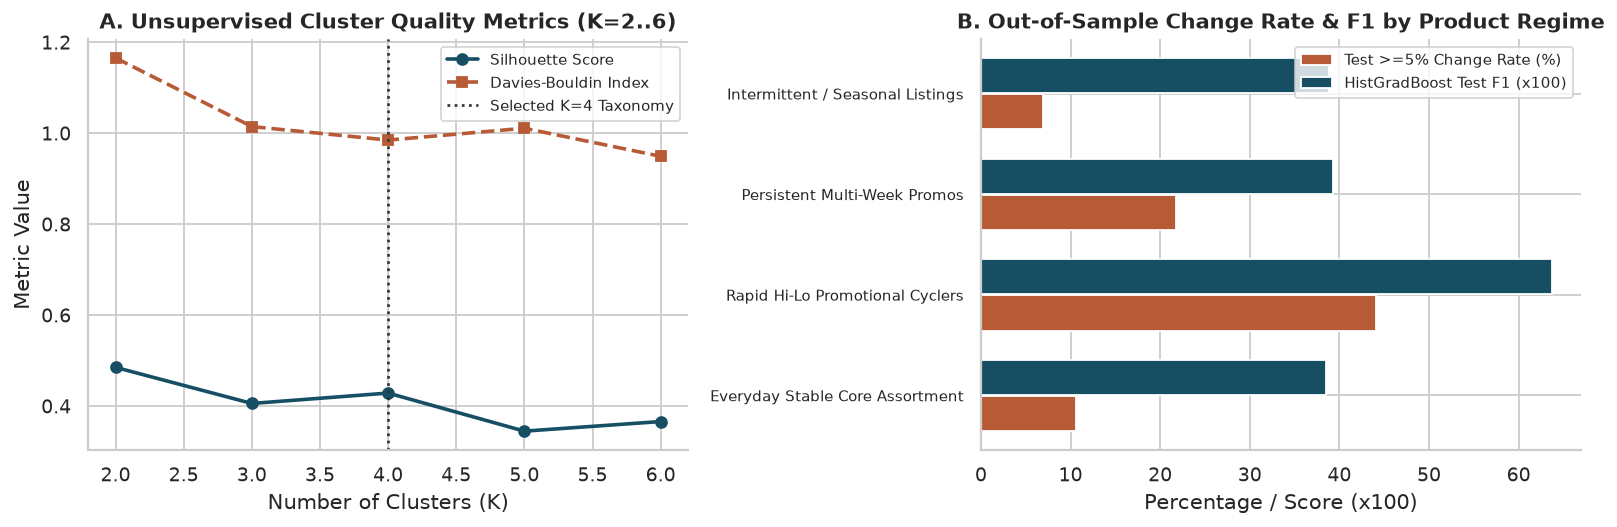

In [12]:
# =============================================================================
# 6.1 Unsupervised K-Means Clustering Metrics & Discovered Product Regimes
# =============================================================================
k_metrics_df = pd.read_csv(P3_DIR / "tables/unsupervised-clustering-metrics.csv")
cluster_profiles_df = pd.read_csv(P3_DIR / "tables/unsupervised-cluster-profiles.csv")

print("1. Unsupervised K-Means Evaluation Metrics across K = 2..6 (on 20,150 Training UPCs):")
display(k_metrics_df.style.format({
    "inertia": "{:,.1f}", "silhouette_score": "{:.4f}",
    "davies_bouldin_index": "{:.4f}", "calinski_harabasz_index": "{:,.1f}"
}))

print("\n2. Discovered Retail Product Pricing Regimes (K = 4) and Out-of-Sample Test Predictability:")
display(cluster_profiles_df[[
    "regime_name", "upcs", "mean_price_usd", "discount_freq_pct", "mean_discount_pct",
    "mean_abs_return_pct", "coverage_pct", "train_target_rate_pct", "test_target_rate_pct",
    "test_histgb_pr_auc", "test_histgb_f1"
]].style.format({
    "upcs": "{:,}", "mean_price_usd": "${:.2f}", "discount_freq_pct": "{:.1f}%",
    "mean_discount_pct": "{:.1f}%", "mean_abs_return_pct": "{:.2f}%", "coverage_pct": "{:.1f}%",
    "train_target_rate_pct": "{:.2f}%", "test_target_rate_pct": "{:.2f}%",
    "test_histgb_pr_auc": "{:.4f}", "test_histgb_f1": "{:.4f}"
}))

fig, axs = plt.subplots(1, 2, figsize=(12.4, 4.2))
axs[0].plot(k_metrics_df["k"], k_metrics_df["silhouette_score"], marker="o", linewidth=2, color=PALETTE[0], label="Silhouette Score")
axs[0].plot(k_metrics_df["k"], k_metrics_df["davies_bouldin_index"], marker="s", linewidth=2, linestyle="--", color=PALETTE[1], label="Davies-Bouldin Index")
axs[0].axvline(4, color="#333", linestyle=":", label="Selected K=4 Taxonomy")
axs[0].set_xlabel("Number of Clusters (K)")
axs[0].set_ylabel("Metric Value")
axs[0].set_title("A. Unsupervised Cluster Quality Metrics (K=2..6)")
axs[0].legend(fontsize=8.5)

y_r = np.arange(len(cluster_profiles_df))
axs[1].barh(y_r - 0.18, cluster_profiles_df["test_target_rate_pct"], height=0.35, label="Test >=5% Change Rate (%)", color=PALETTE[1])
axs[1].barh(y_r + 0.18, cluster_profiles_df["test_histgb_f1"] * 100.0, height=0.35, label="HistGradBoost Test F1 (x100)", color=PALETTE[0])
axs[1].set_yticks(y_r)
axs[1].set_yticklabels([r.split(": ")[1] for r in cluster_profiles_df["regime_name"]], fontsize=8.5)
axs[1].set_xlabel("Percentage / Score (x100)")
axs[1].set_title("B. Out-of-Sample Change Rate & F1 by Product Regime")
axs[1].legend(fontsize=8.5)

fig.tight_layout()
plt.show()

---
## 7. Discussion, Model Recommendation & Conclusion

### Key Findings & Model Recommendation
1. **Recommended Model — Histogram-Based Gradient Boosting (`HistGradientBoostingClassifier`):**
   - Across both 5-fold expanding-window temporal cross-validation and the 46,511-row held-out test set, **Histogram-Based Gradient Boosting** coupled with **Random Forest** achieves the strongest ranking and classification performance, substantially outperforming linear models (`LogisticRegression`, `LinearSVC`), single `DecisionTree`, and the domain `Observed Discount Heuristic`.
   - Depending on operational priorities, we recommend deploying `HistGradientBoostingClassifier` with **CV-tuned probability thresholding** when balancing Precision and Recall to maximize $F_1$, or with **Balanced Class Weights** (`0: 0.567, 1: 4.212`) when downstream alerting requires higher Recall ($\sim 60\%$) and Balanced Accuracy ($\sim 71.7\%$).
2. **Why Non-Linear Tree Ensembles Outperform Linear Models:**
   - Grocery price changes follow asymmetric **Hi-Lo promotional cycles**: an active discount (`discount_depth > 0`) paired with a recent negative price drop (`return_7d < 0`) strongly signals an impending post-sale price rollback to regular price, whereas an undiscounted item in a high-promotion category (`Soda Pop`, `Frozen Dessert`, `Cookies`) with high historical volatility (`mean_abs_change_4`) has elevated probability of entering a new sale. Boosted trees capture these multi-way threshold interactions directly.
3. **Methodological Lessons Learned:**
   - **Preventing Temporal Leakage:** Enforcing $\max(\text{train.target\_date}) \le \min(\text{test.date})$ and refitting imputation, scaling, and encoding inside each expanding fold prevents optimistic bias.
   - **Missingness as Structural Signal:** Retaining binary missingness indicators (`missingindicator_volatility_4`, `missingindicator_return_7d`) preserves information about observation sparsity and explains why keeping both `mean_abs_change_4` and `volatility_4` ($r = 0.98$ when co-observed) does not degrade boosted tree performance.